In [1]:
# Proyecto Final - Análisis y Predicción de Ventas

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
import os

print("Python está buscando los archivos en:")
print(os.getcwd())

print("\nArchivos que encuentra en esa carpeta:")
print(os.listdir())

Python está buscando los archivos en:
C:\Users\Genesis

Archivos que encuentra en esa carpeta:
['.anaconda', '.conda', '.condarc', '.continuum', '.dia', '.ipynb_checkpoints', '.ipython', '.jupyter', '.mamba', '.matplotlib', '.ms-ad', '.virtual_documents', '.vscode', '8836201-6f9306ad21398ea43cba4f7d537619d0e07d5ae3.zip', 'Amazon.xlsx', 'anaconda3', 'anaconda_projects', 'ansel', 'AppData', 'apps.csv', 'Aprendizaje Supervisado.ipynb', 'archive (1).zip', 'Base.db', 'Cientifico de datos M40 Customers.csv', 'Cientifico de datos M53 - Advertising.csv', 'co2-mm-mlo.csv', 'co2-mm-mlo_csv.csv', 'Configuración local', 'Contacts', 'Cookies', 'dataset_consolidado.csv', 'data_description.txt', 'Datos de programa', 'Desktop', 'DIM_CALENDAR (2) (3).xlsx', 'DIM_CALENDAR (2).xlsx', 'DIM_CATEGORY (2) (1).csv', 'DIM_CATEGORY (2).csv', 'DIM_PRODUCT (1) (4).xlsx', 'DIM_PRODUCT (1).xlsx', 'DIM_SEGMENT (1) (3).xlsx', 'DIM_SEGMENT (1).xlsx', 'Documents', 'Downloads', 'drugs.csv', 'Entorno de red', 'FACT_SALES

In [3]:
fact_sales = pd.read_csv("FACT_SALES (1) (4).csv")

dim_product = pd.read_excel("DIM_PRODUCT (1) (4).xlsx")

dim_calendar = pd.read_excel("DIM_CALENDAR (2) (3).xlsx")

dim_category = pd.read_csv("DIM_CATEGORY (2) (1).csv")

dim_segment = pd.read_excel("DIM_SEGMENT (1) (3).xlsx")

print("Archivos cargados correctamente.")

Archivos cargados correctamente.


In [4]:
print("FACT_SALES:", fact_sales.shape)
print("DIM_PRODUCT:", dim_product.shape)
print("DIM_CALENDAR:", dim_calendar.shape)
print("DIM_CATEGORY:", dim_category.shape)
print("DIM_SEGMENT:", dim_segment.shape)

FACT_SALES: (122002, 6)
DIM_PRODUCT: (505, 9)
DIM_CALENDAR: (156, 5)
DIM_CATEGORY: (5, 2)
DIM_SEGMENT: (53, 6)


In [5]:
print("Columnas de FACT_SALES:")
print(fact_sales.columns.tolist())

print("\nColumnas de DIM_PRODUCT:")
print(dim_product.columns.tolist())

print("\nColumnas de DIM_CALENDAR:")
print(dim_calendar.columns.tolist())

print("\nColumnas de DIM_CATEGORY:")
print(dim_category.columns.tolist())

print("\nColumnas de DIM_SEGMENT:")
print(dim_segment.columns.tolist())

Columnas de FACT_SALES:
['WEEK', 'ITEM_CODE', 'TOTAL_UNIT_SALES', 'TOTAL_VALUE_SALES', 'TOTAL_UNIT_AVG_WEEKLY_SALES', 'REGION']

Columnas de DIM_PRODUCT:
['MANUFACTURER', 'BRAND', 'ITEM', 'ITEM_DESCRIPTION', 'CATEGORY', 'FORMAT', 'ATTR1', 'ATTR2', 'ATTR3']

Columnas de DIM_CALENDAR:
['WEEK', 'YEAR', 'MONTH', 'WEEK_NUMBER', 'DATE']

Columnas de DIM_CATEGORY:
['ID_CATEGORY', 'CATEGORY']

Columnas de DIM_SEGMENT:
['CATEGORY', 'ATTR1', 'ATTR2', 'ATTR3', 'FORMAT', 'SEGMENT']


In [6]:
print("VALORES NULOS EN FACT_SALES")
print(fact_sales.isna().sum())

print("\nVALORES NULOS EN DIM_PRODUCT")
print(dim_product.isna().sum())

print("\nVALORES NULOS EN DIM_CALENDAR")
print(dim_calendar.isna().sum())

print("\nVALORES NULOS EN DIM_CATEGORY")
print(dim_category.isna().sum())

print("\nVALORES NULOS EN DIM_SEGMENT")
print(dim_segment.isna().sum())

VALORES NULOS EN FACT_SALES
WEEK                           0
ITEM_CODE                      0
TOTAL_UNIT_SALES               0
TOTAL_VALUE_SALES              0
TOTAL_UNIT_AVG_WEEKLY_SALES    0
REGION                         0
dtype: int64

VALORES NULOS EN DIM_PRODUCT
MANUFACTURER        0
BRAND               0
ITEM                2
ITEM_DESCRIPTION    0
CATEGORY            0
FORMAT              0
ATTR1               6
ATTR2               0
ATTR3               6
dtype: int64

VALORES NULOS EN DIM_CALENDAR
WEEK           0
YEAR           0
MONTH          0
WEEK_NUMBER    0
DATE           0
dtype: int64

VALORES NULOS EN DIM_CATEGORY
ID_CATEGORY    0
CATEGORY       0
dtype: int64

VALORES NULOS EN DIM_SEGMENT
CATEGORY    0
ATTR1       0
ATTR2       0
ATTR3       1
FORMAT      0
SEGMENT     0
dtype: int64


In [7]:
print("Registros con valores nulos en DIM_PRODUCT:")
display(dim_product[dim_product.isna().any(axis=1)])

print("\nRegistros con valores nulos en DIM_SEGMENT:")
display(dim_segment[dim_segment.isna().any(axis=1)])

Registros con valores nulos en DIM_PRODUCT:


,MANUFACTURER,BRAND,ITEM,ITEM_DESCRIPTION,CATEGORY,FORMAT,ATTR1,ATTR2,ATTR3
33,WHITE MAGIC,WHITE MAGIC,0079893431208,9WHITE MAGIC BOT.PLAS 3970ML IMP 0079893431208,1,LIQUIDO,NaN,CLORO,NaN
107,INDS. ALEN,CLORALEX,7501025401023,CLORALEX EXTRA SENSACION FRUTALES BOT PLAST 95...,1,LIQUIDO,NaN,CLORO,NaN
143,INDS. ALEN,BLANCATEL,7501025402259,BLANCATEL BLANQUEADOR BOTELLA 1.8LT 7501025402259,1,LIQUIDO,NaN,CLORO,NaN
343,CLOROX,CLOROX,7501071901591,CLOROX BLANQUEADOR PARAISO TROPICAL 3800 ML NA...,1,LIQUIDO,NaN,CLORO,NaN
469,OTHERS FABRICANTE UNIF.,OTHERS MARCA UNIF.,7502217411776,KLEEN CLORO BOTELLA 1000 ML NAL 7502217411776,1,LIQUIDO,NaN,CLORO,NaN
495,IBERIA,IBERIA,8411660040503,9IBERIA BLANQUEADOR POLVO 250 GR IMP 841166004...,1,POLVO,NaN,CLORO,NaN
502,INDS. ALEN,CLORALEX,NaN,CLORALEX EL RENDIDOR BOT PLAST 2LT,1,LIQUIDO,CLORO,CLORO,NO DEFINIDO
503,CLOROX,CLOROX,NaN,CLOROX MASCOTAS BLANQUEADOR+DETERGENTE GALON 10L,1,LIQUIDO,CLORO,CLORO,MASCOTAS



Registros con valores nulos en DIM_SEGMENT:


,CATEGORY,ATTR1,ATTR2,ATTR3,FORMAT,SEGMENT
10,1,CLORO,CLORO,NaN,LIQUIDO,BLEACH


In [8]:
print("Duplicados en FACT_SALES:", fact_sales.duplicated().sum())

print("Duplicados en DIM_PRODUCT:", dim_product.duplicated().sum())

print("Duplicados en DIM_CALENDAR:", dim_calendar.duplicated().sum())

print("Duplicados en DIM_CATEGORY:", dim_category.duplicated().sum())

print("Duplicados en DIM_SEGMENT:", dim_segment.duplicated().sum())

Duplicados en FACT_SALES: 0
Duplicados en DIM_PRODUCT: 0
Duplicados en DIM_CALENDAR: 0
Duplicados en DIM_CATEGORY: 0
Duplicados en DIM_SEGMENT: 0


In [9]:
print("Primeros registros de DIM_CALENDAR:")
display(dim_calendar.head())

print("\nTipos de datos:")
print(dim_calendar.dtypes)

print("\nRango de fechas:")
print("Fecha inicial:", dim_calendar["DATE"].min())
print("Fecha final:", dim_calendar["DATE"].max())

Primeros registros de DIM_CALENDAR:


,WEEK,YEAR,MONTH,WEEK_NUMBER,DATE
0,01-21,2021,1,1,2021-01-10
1,02-21,2021,1,2,2021-01-17
2,03-21,2021,1,3,2021-01-24
3,04-21,2021,1,4,2021-01-31
4,05-21,2021,2,5,2021-02-07



Tipos de datos:
WEEK                      str
YEAR                    int64
MONTH                   int64
WEEK_NUMBER             int64
DATE           datetime64[us]
dtype: object

Rango de fechas:
Fecha inicial: 2021-01-10 00:00:00
Fecha final: 2024-01-01 00:00:00


In [10]:
print("Resumen estadístico de FACT_SALES:")

display(
    fact_sales[
        [
            "TOTAL_UNIT_SALES",
            "TOTAL_VALUE_SALES",
            "TOTAL_UNIT_AVG_WEEKLY_SALES"
        ]
    ].describe()
)

Resumen estadístico de FACT_SALES:


,TOTAL_UNIT_SALES,TOTAL_VALUE_SALES,TOTAL_UNIT_AVG_WEEKLY_SALES
count,122002.000000,122002.000000,122002.000000
mean,3.211097,90.513761,10.099904
std,14.496009,350.236505,22.650142
min,0.000000,0.001000,0.042000
25%,0.063000,2.662000,2.316000
50%,0.367000,16.812000,3.993500
75%,1.520000,62.961500,8.898000
max,504.681000,12236.759000,794.000000


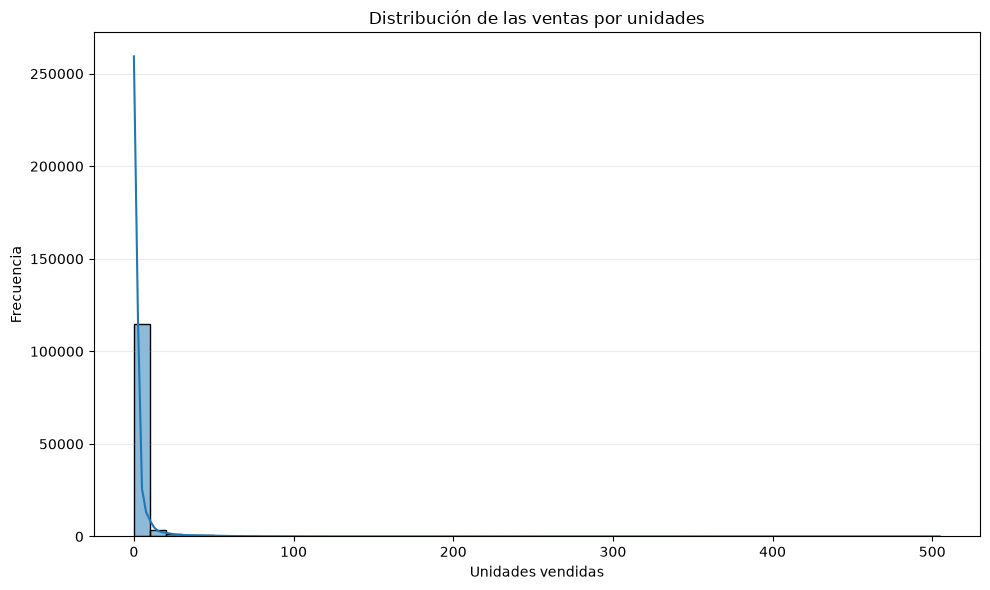

In [11]:
plt.figure(figsize=(10, 6))

sns.histplot(
    fact_sales["TOTAL_UNIT_SALES"],
    bins=50,
    kde=True
)

plt.title("Distribución de las ventas por unidades")
plt.xlabel("Unidades vendidas")
plt.ylabel("Frecuencia")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

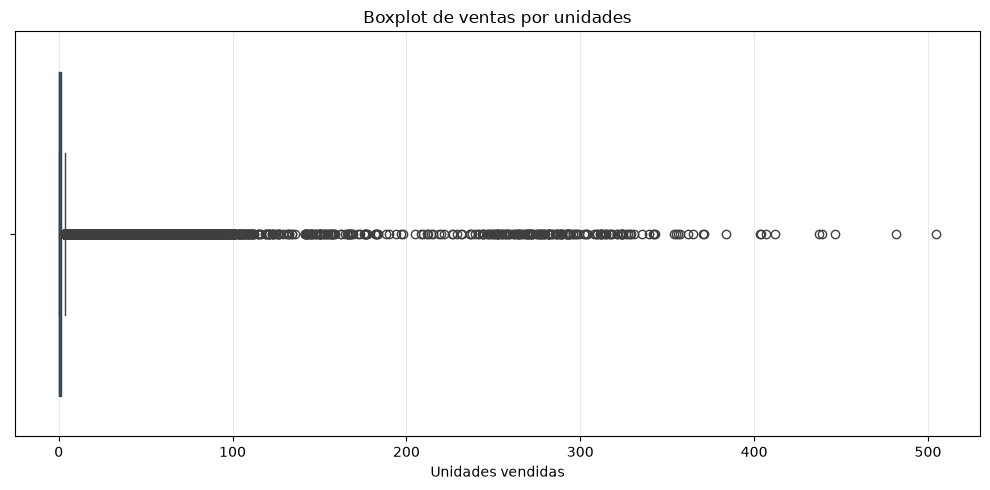

In [12]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    x=fact_sales["TOTAL_UNIT_SALES"]
)

plt.title("Boxplot de ventas por unidades")
plt.xlabel("Unidades vendidas")
plt.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

In [13]:
print("Categorías disponibles:")

display(dim_category)

Categorías disponibles:


,ID_CATEGORY,CATEGORY
0,1,FABRIC TREATMENT and SANIT\r\n
1,2,AIR CARE
2,3,LAVAVAJILLAS
3,4,MEGA SUPERFICIES
4,5,LAVATORY CARE & BRC


In [14]:
dim_category["CATEGORY"] = (
    dim_category["CATEGORY"]
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

print("Categorías después de la limpieza:")

display(dim_category)

Categorías después de la limpieza:


,ID_CATEGORY,CATEGORY
0,1,FABRIC TREATMENT and SANIT
1,2,AIR CARE
2,3,LAVAVAJILLAS
3,4,MEGA SUPERFICIES
4,5,LAVATORY CARE & BRC


In [15]:
dim_product["ITEM_CODE_BASE"] = (
    dim_product["ITEM_DESCRIPTION"]
    .str.extract(r"(\d{10,13})", expand=False)
)

fact_sales["ITEM_CODE_BASE"] = (
    fact_sales["ITEM_CODE"]
    .astype(str)
    .str.extract(r"(\d{10,13})", expand=False)
)

print("Código de producto preparado en ambas tablas.")

display(
    fact_sales[
        ["ITEM_CODE", "ITEM_CODE_BASE"]
    ].head()
)

display(
    dim_product[
        ["ITEM", "ITEM_CODE_BASE", "BRAND"]
    ].head()
)

Código de producto preparado en ambas tablas.


,ITEM_CODE,ITEM_CODE_BASE
0,7501058792808BP2,7501058792808
1,7501058715883,7501058715883
2,7702626213774,7702626213774
3,7501058716422,7501058716422
4,7501058784353,7501058784353


,ITEM,ITEM_CODE_BASE,BRAND
0,0000075000592,0000075000592,CLORALEX
1,0000075000608,0000075000608,CLORALEX
2,0000075000615,0000075000615,CLORALEX
3,0000075000622,0000075000622,CLORALEX
4,0000075000639,0000075000639,CLORALEX


In [16]:
dim_product["ITEM_CODE_BASE"] = (
    dim_product["ITEM_CODE_BASE"]
    .astype(str)
    .str.lstrip("0")
)

fact_sales["ITEM_CODE_BASE"] = (
    fact_sales["ITEM_CODE_BASE"]
    .astype(str)
    .str.lstrip("0")
)

print("Códigos homologados correctamente.")

display(
    dim_product[
        ["ITEM", "ITEM_CODE_BASE", "BRAND"]
    ].head()
)

display(
    fact_sales[
        ["ITEM_CODE", "ITEM_CODE_BASE"]
    ].head()
)

Códigos homologados correctamente.


,ITEM,ITEM_CODE_BASE,BRAND
0,0000075000592,75000592,CLORALEX
1,0000075000608,75000608,CLORALEX
2,0000075000615,75000615,CLORALEX
3,0000075000622,75000622,CLORALEX
4,0000075000639,75000639,CLORALEX


,ITEM_CODE,ITEM_CODE_BASE
0,7501058792808BP2,7501058792808
1,7501058715883,7501058715883
2,7702626213774,7702626213774
3,7501058716422,7501058716422
4,7501058784353,7501058784353


In [17]:
codigos_productos = set(dim_product["ITEM_CODE_BASE"].dropna())

fact_sales["PRODUCTO_EN_DIM"] = (
    fact_sales["ITEM_CODE_BASE"].isin(codigos_productos)
)

print("Registros de FACT_SALES con producto encontrado:")
print(fact_sales["PRODUCTO_EN_DIM"].value_counts())

print("\nPorcentaje de coincidencias:")
print(
    fact_sales["PRODUCTO_EN_DIM"].mean() * 100,
    "%"
)

Registros de FACT_SALES con producto encontrado:
PRODUCTO_EN_DIM
True    122002
Name: count, dtype: int64

Porcentaje de coincidencias:
100.0 %


In [18]:
ventas_productos = fact_sales.merge(
    dim_product,
    on="ITEM_CODE_BASE",
    how="left"
)

print("Tabla consolidada:")
print(ventas_productos.shape)

display(
    ventas_productos[
        [
            "WEEK",
            "ITEM_CODE",
            "BRAND",
            "CATEGORY",
            "FORMAT",
            "REGION",
            "TOTAL_UNIT_SALES",
            "TOTAL_VALUE_SALES"
        ]
    ].head()
)

Tabla consolidada:
(130338, 17)


,WEEK,ITEM_CODE,BRAND,CATEGORY,FORMAT,REGION,TOTAL_UNIT_SALES,TOTAL_VALUE_SALES
0,34-22,7501058792808BP2,VANISH,1,POLVO,TOTAL AUTOS AREA 5,0.006,0.139
1,34-22,7501058792808BP2,VANISH,1,POLVO,TOTAL AUTOS AREA 5,0.006,0.139
2,34-22,7501058715883,VANISH,1,POLVO,TOTAL AUTOS AREA 5,0.487,116.519
3,34-22,7702626213774,VANISH,1,POLVO,TOTAL AUTOS AREA 5,1.391,68.453
4,34-22,7501058716422,VANISH,1,POLVO,TOTAL AUTOS AREA 5,0.022,1.481


In [19]:
# Recuperar el código completo del producto
dim_product["ITEM_CODE_MATCH"] = (
    dim_product["ITEM"]
    .astype(str)
    .str.strip()
)

fact_sales["ITEM_CODE_MATCH"] = (
    fact_sales["ITEM_CODE"]
    .astype(str)
    .str.strip()
)

print("Ejemplo DIM_PRODUCT:")
display(dim_product[["ITEM", "ITEM_CODE_MATCH"]].head())

print("\nEjemplo FACT_SALES:")
display(fact_sales[["ITEM_CODE", "ITEM_CODE_MATCH"]].head())

Ejemplo DIM_PRODUCT:


,ITEM,ITEM_CODE_MATCH
0,0000075000592,0000075000592
1,0000075000608,0000075000608
2,0000075000615,0000075000615
3,0000075000622,0000075000622
4,0000075000639,0000075000639



Ejemplo FACT_SALES:


,ITEM_CODE,ITEM_CODE_MATCH
0,7501058792808BP2,7501058792808BP2
1,7501058715883,7501058715883
2,7702626213774,7702626213774
3,7501058716422,7501058716422
4,7501058784353,7501058784353


In [20]:
ventas_productos = fact_sales.merge(
    dim_product,
    on="ITEM_CODE_MATCH",
    how="left"
)

print("Filas de FACT_SALES:", len(fact_sales))
print("Filas después del merge:", len(ventas_productos))

print("\nProductos sin coincidencia:")
print(ventas_productos["BRAND"].isna().sum())

Filas de FACT_SALES: 122002
Filas después del merge: 122002

Productos sin coincidencia:
0


In [21]:
ventas_completas = ventas_productos.merge(
    dim_category,
    left_on="CATEGORY",
    right_on="ID_CATEGORY",
    how="left"
)

# Renombrar la categoría para que sea más fácil de identificar
ventas_completas = ventas_completas.rename(
    columns={"CATEGORY_y": "CATEGORY_NAME"}
)

print("Filas de la tabla:", len(ventas_completas))
print("Categorías sin coincidencia:", ventas_completas["CATEGORY_NAME"].isna().sum())

display(
    ventas_completas[
        [
            "WEEK",
            "BRAND",
            "CATEGORY_NAME",
            "FORMAT",
            "REGION",
            "TOTAL_UNIT_SALES",
            "TOTAL_VALUE_SALES"
        ]
    ].head()
)

Filas de la tabla: 122002
Categorías sin coincidencia: 0


,WEEK,BRAND,CATEGORY_NAME,FORMAT,REGION,TOTAL_UNIT_SALES,TOTAL_VALUE_SALES
0,34-22,VANISH,FABRIC TREATMENT and SANIT,POLVO,TOTAL AUTOS AREA 5,0.006,0.139
1,34-22,VANISH,FABRIC TREATMENT and SANIT,POLVO,TOTAL AUTOS AREA 5,0.487,116.519
2,34-22,VANISH,FABRIC TREATMENT and SANIT,POLVO,TOTAL AUTOS AREA 5,1.391,68.453
3,34-22,VANISH,FABRIC TREATMENT and SANIT,POLVO,TOTAL AUTOS AREA 5,0.022,1.481
4,34-22,VANISH,FABRIC TREATMENT and SANIT,POLVO,TOTAL AUTOS AREA 5,2.037,182.839


In [22]:
ventas_completas = ventas_completas.merge(
    dim_calendar,
    on="WEEK",
    how="left"
)

print("Filas de la tabla:", len(ventas_completas))
print("Fechas sin coincidencia:", ventas_completas["DATE"].isna().sum())

display(
    ventas_completas[
        [
            "WEEK",
            "DATE",
            "YEAR",
            "MONTH",
            "BRAND",
            "CATEGORY_NAME",
            "REGION",
            "TOTAL_UNIT_SALES",
            "TOTAL_VALUE_SALES"
        ]
    ].head()
)

Filas de la tabla: 122002
Fechas sin coincidencia: 0


,WEEK,DATE,YEAR,MONTH,BRAND,CATEGORY_NAME,REGION,TOTAL_UNIT_SALES,TOTAL_VALUE_SALES
0,34-22,2022-08-28,2022,8,VANISH,FABRIC TREATMENT and SANIT,TOTAL AUTOS AREA 5,0.006,0.139
1,34-22,2022-08-28,2022,8,VANISH,FABRIC TREATMENT and SANIT,TOTAL AUTOS AREA 5,0.487,116.519
2,34-22,2022-08-28,2022,8,VANISH,FABRIC TREATMENT and SANIT,TOTAL AUTOS AREA 5,1.391,68.453
3,34-22,2022-08-28,2022,8,VANISH,FABRIC TREATMENT and SANIT,TOTAL AUTOS AREA 5,0.022,1.481
4,34-22,2022-08-28,2022,8,VANISH,FABRIC TREATMENT and SANIT,TOTAL AUTOS AREA 5,2.037,182.839


In [23]:
ventas_categoria = (
    ventas_completas
    .groupby("CATEGORY_NAME", as_index=False)
    .agg(
        VENTAS_UNIDADES=("TOTAL_UNIT_SALES", "sum"),
        VENTAS_VALOR=("TOTAL_VALUE_SALES", "sum")
    )
    .sort_values("VENTAS_VALOR", ascending=False)
)

display(ventas_categoria)

,CATEGORY_NAME,VENTAS_UNIDADES,VENTAS_VALOR
0,FABRIC TREATMENT and SANIT,391760.228,1.104286e+07


In [24]:
print("Número de categorías:", ventas_completas["CATEGORY_NAME"].nunique())

print("\nCategorías encontradas:")
print(ventas_completas["CATEGORY_NAME"].value_counts(dropna=False))

Número de categorías: 1

Categorías encontradas:
CATEGORY_NAME
FABRIC TREATMENT and SANIT    122002
Name: count, dtype: int64


In [25]:
# Volver a crear la tabla con las categorías correctamente
ventas_completas = ventas_productos.merge(
    dim_category,
    left_on="CATEGORY",
    right_on="ID_CATEGORY",
    how="left"
)

# Renombrar la columna CATEGORY de DIM_CATEGORY
ventas_completas = ventas_completas.rename(
    columns={"CATEGORY_y": "CATEGORY_NAME"}
)

print("Columnas de categoría:")
print(
    ventas_completas[
        ["CATEGORY_x", "ID_CATEGORY", "CATEGORY_NAME"]
    ].head()
)

print("\nNúmero de categorías:", ventas_completas["CATEGORY_NAME"].nunique())

print("\nCategorías encontradas:")
print(ventas_completas["CATEGORY_NAME"].value_counts())

Columnas de categoría:
   CATEGORY_x  ID_CATEGORY               CATEGORY_NAME
0           1            1  FABRIC TREATMENT and SANIT
1           1            1  FABRIC TREATMENT and SANIT
2           1            1  FABRIC TREATMENT and SANIT
3           1            1  FABRIC TREATMENT and SANIT
4           1            1  FABRIC TREATMENT and SANIT

Número de categorías: 1

Categorías encontradas:
CATEGORY_NAME
FABRIC TREATMENT and SANIT    122002
Name: count, dtype: int64


In [26]:
print("Categorías en DIM_PRODUCT:")
print(dim_product["CATEGORY"].value_counts(dropna=False))

print("\nCategorías en DIM_CATEGORY:")
display(dim_category)

Categorías en DIM_PRODUCT:
CATEGORY
1    505
Name: count, dtype: int64

Categorías en DIM_CATEGORY:


,ID_CATEGORY,CATEGORY
0,1,FABRIC TREATMENT and SANIT
1,2,AIR CARE
2,3,LAVAVAJILLAS
3,4,MEGA SUPERFICIES
4,5,LAVATORY CARE & BRC


In [27]:
print("Filas de DIM_SEGMENT:", len(dim_segment))

print("\nCategorías:")
print(dim_segment["CATEGORY"].value_counts(dropna=False))

print("\nPrimeros registros:")
display(dim_segment.head(15))

Filas de DIM_SEGMENT: 53

Categorías:
CATEGORY
1    53
Name: count, dtype: int64

Primeros registros:


,CATEGORY,ATTR1,ATTR2,ATTR3,FORMAT,SEGMENT
0,1,CLORO,CLORO,BAMBINO,LIQUIDO,BLEACH
1,1,CLORO,CLORO,GERMICIDA,LIQUIDO,BLEACH
2,1,CLORO,CLORO,MASCOTAS,LIQUIDO,BLEACH
3,1,CLORO,CLORO,MULTIUSOS,GEL,BLEACH
4,1,CLORO,CLORO,MULTIUSOS,LIQUIDO,BLEACH
5,1,CLORO,CLORO,NO DEFINIDO,LIQUIDO,BLEACH
6,1,CLORO,CLORO,NO DEFINIDO,POLVO,BLEACH
7,1,CLORO,CLORO,OTR. TIPOS,LIQUIDO,BLEACH
8,1,CLORO,CLORO,OTR. TIPOS,POLVO,BLEACH
9,1,CLORO,CLORO,ROPA BEBE,LIQUIDO,BLEACH


In [28]:
ventas_region = (
    ventas_completas
    .groupby("REGION", as_index=False)
    .agg(
        VENTAS_UNIDADES=("TOTAL_UNIT_SALES", "sum"),
        VENTAS_VALOR=("TOTAL_VALUE_SALES", "sum")
    )
    .sort_values("VENTAS_VALOR", ascending=False)
)

display(ventas_region)

,REGION,VENTAS_UNIDADES,VENTAS_VALOR
6,TOTAL AUTOS SCANNING MEXICO,195880.054,5521429.320
1,TOTAL AUTOS AREA 2,45319.916,1188796.150
4,TOTAL AUTOS AREA 5,36266.900,1153335.538
5,TOTAL AUTOS AREA 6,38585.222,983957.571
2,TOTAL AUTOS AREA 3,25896.054,803655.337
0,TOTAL AUTOS AREA 1,25791.933,714249.979
3,TOTAL AUTOS AREA 4,24020.149,677435.998


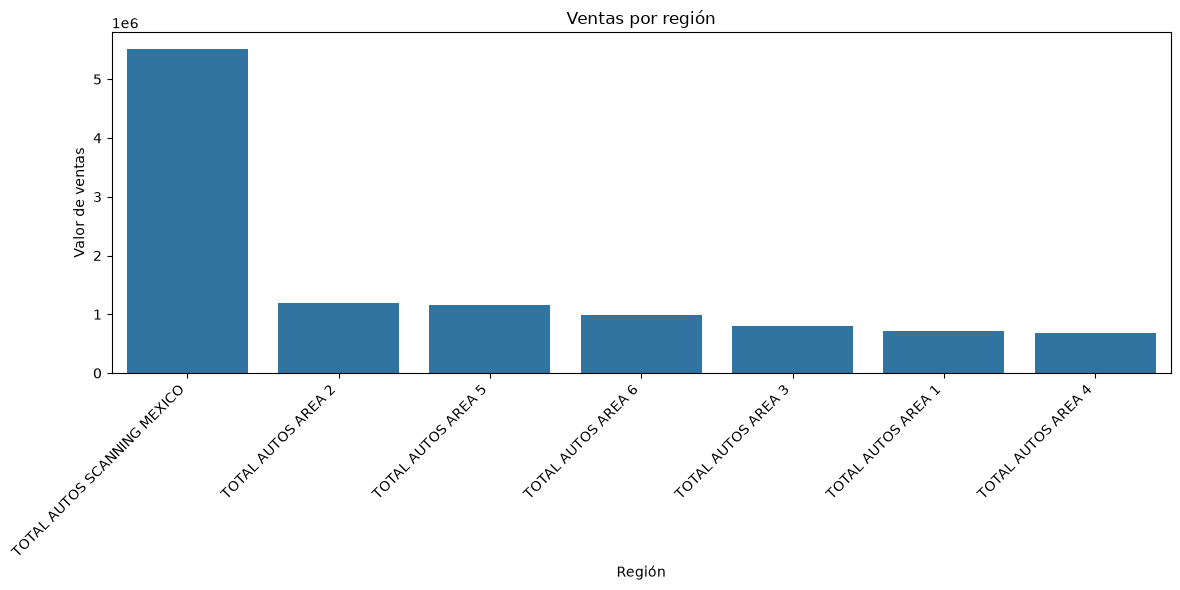

In [29]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=ventas_region,
    x="REGION",
    y="VENTAS_VALOR"
)

plt.title("Ventas por región")
plt.xlabel("Región")
plt.ylabel("Valor de ventas")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [30]:
ventas_marca = (
    ventas_completas
    .groupby("BRAND", as_index=False)
    .agg(
        VENTAS_UNIDADES=("TOTAL_UNIT_SALES", "sum"),
        VENTAS_VALOR=("TOTAL_VALUE_SALES", "sum")
    )
    .sort_values("VENTAS_VALOR", ascending=False)
)

display(ventas_marca)

,BRAND,VENTAS_UNIDADES,VENTAS_VALOR
4,CLORALEX,223300.668,5393618.509
23,VANISH,55332.944,2168289.525
6,CLOROX,47881.201,1371751.724
2,BLANCATEL,20611.297,652484.021
17,OXI CLEAN,6079.374,436970.719
9,DR.BECKMANN,5229.318,279719.229
0,BANDERA,12123.081,269936.898
14,LOS PATITOS,6781.689,142745.659
3,CLARASOL,9821.125,141012.175
15,LYSOL,529.490,70557.346


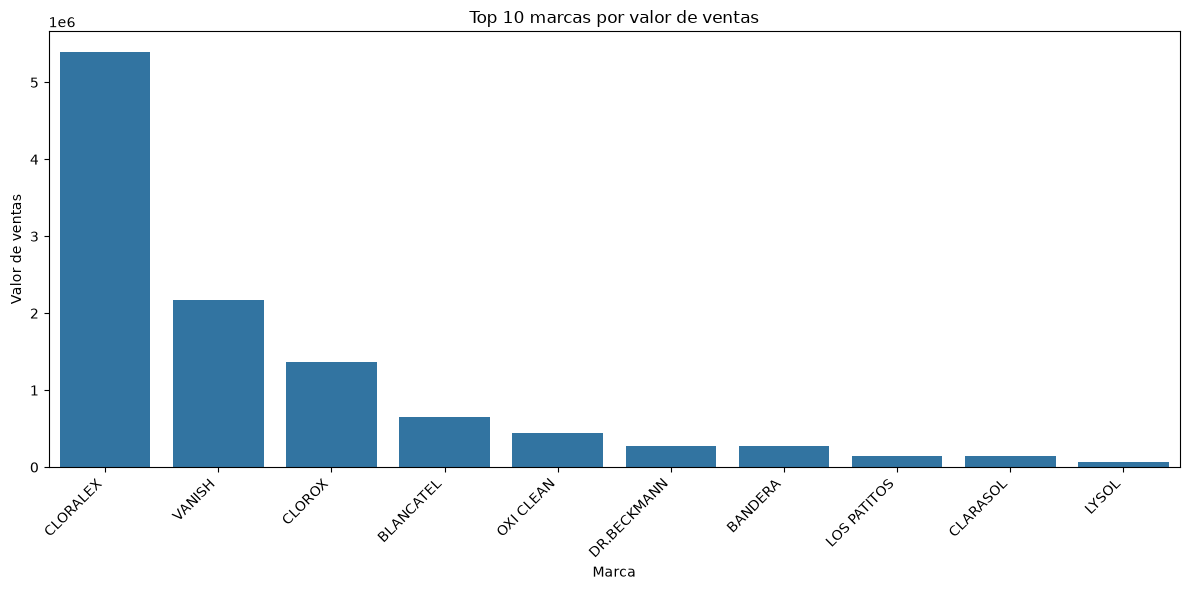

In [31]:
top_10_marcas = ventas_marca.head(10)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_10_marcas,
    x="BRAND",
    y="VENTAS_VALOR"
)

plt.title("Top 10 marcas por valor de ventas")
plt.xlabel("Marca")
plt.ylabel("Valor de ventas")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [32]:
ventas_completas = ventas_completas.merge(
    dim_calendar,
    on="WEEK",
    how="left"
)

print("Filas de la tabla:", len(ventas_completas))
print("Fechas sin coincidencia:", ventas_completas["DATE"].isna().sum())

Filas de la tabla: 122002
Fechas sin coincidencia: 0


In [33]:
ventas_semana = (
    ventas_completas
    .groupby("DATE", as_index=False)
    .agg(
        VENTAS_UNIDADES=("TOTAL_UNIT_SALES", "sum"),
        VENTAS_VALOR=("TOTAL_VALUE_SALES", "sum")
    )
    .sort_values("DATE")
)

display(ventas_semana.head())
print("Número de semanas:", len(ventas_semana))

,DATE,VENTAS_UNIDADES,VENTAS_VALOR
0,2022-01-09,5661.824,151538.922
1,2022-01-16,5686.147,146996.991
2,2022-01-23,4844.874,125351.336
3,2022-01-30,4793.584,123945.617
4,2022-02-06,5021.274,129841.767


Número de semanas: 80


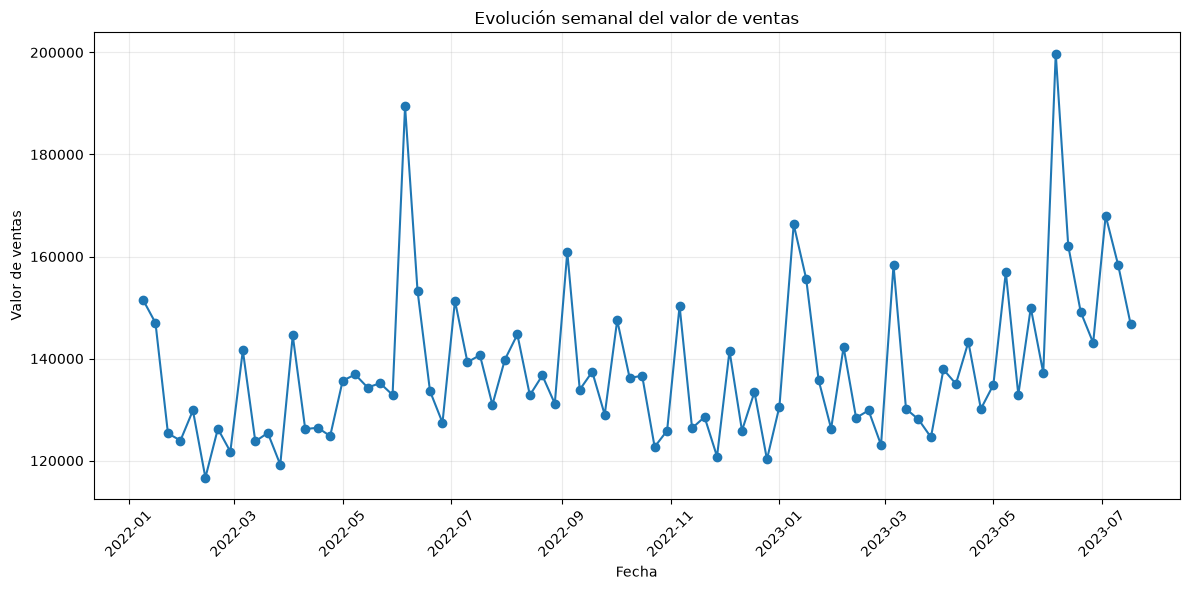

In [34]:
plt.figure(figsize=(12, 6))

plt.plot(
    ventas_semana["DATE"],
    ventas_semana["VENTAS_VALOR"],
    marker="o",
    linewidth=1.5
)

plt.title("Evolución semanal del valor de ventas")
plt.xlabel("Fecha")
plt.ylabel("Valor de ventas")
plt.xticks(rotation=45)
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

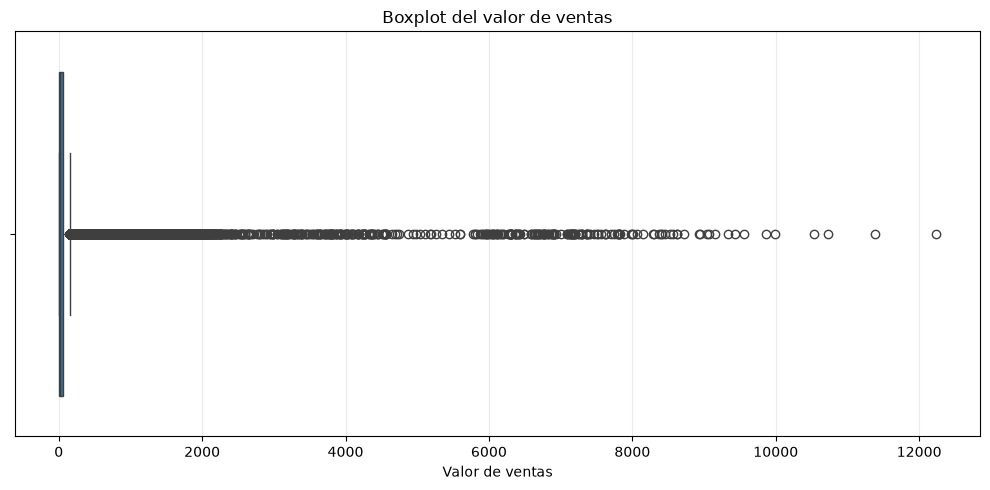

In [35]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    x=ventas_completas["TOTAL_VALUE_SALES"]
)

plt.title("Boxplot del valor de ventas")
plt.xlabel("Valor de ventas")
plt.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

In [36]:
datos_kmeans = (
    ventas_completas
    .groupby(["ITEM_CODE_MATCH", "BRAND"], as_index=False)
    .agg(
        VENTAS_UNIDADES=("TOTAL_UNIT_SALES", "sum"),
        VENTAS_VALOR=("TOTAL_VALUE_SALES", "sum"),
        PROMEDIO_UNIDADES=("TOTAL_UNIT_AVG_WEEKLY_SALES", "mean"),
        SEMANAS_ACTIVAS=("WEEK", "nunique")
    )
)

print("Productos para clustering:", len(datos_kmeans))

display(datos_kmeans.head())

Productos para clustering: 350


,ITEM_CODE_MATCH,BRAND,VENTAS_UNIDADES,VENTAS_VALOR,PROMEDIO_UNIDADES,SEMANAS_ACTIVAS
0,0000075000592,CLORALEX,6.042,24.663,4.860489,65
1,0000075000608,CLORALEX,1423.786,12423.156,35.166597,80
2,0000075000615,CLORALEX,46461.839,658584.568,92.527904,80
3,0000075000622,CLORALEX,48445.151,1139233.787,112.098525,80
4,0000075000639,CLORALEX,28334.417,1146849.632,60.226977,80


In [37]:
from sklearn.preprocessing import StandardScaler

variables_kmeans = [
    "VENTAS_UNIDADES",
    "VENTAS_VALOR",
    "PROMEDIO_UNIDADES",
    "SEMANAS_ACTIVAS"
]

scaler = StandardScaler()

X_kmeans = scaler.fit_transform(
    datos_kmeans[variables_kmeans]
)

print("Variables estandarizadas correctamente.")
print("Dimensiones de X:", X_kmeans.shape)

Variables estandarizadas correctamente.
Dimensiones de X: (350, 4)


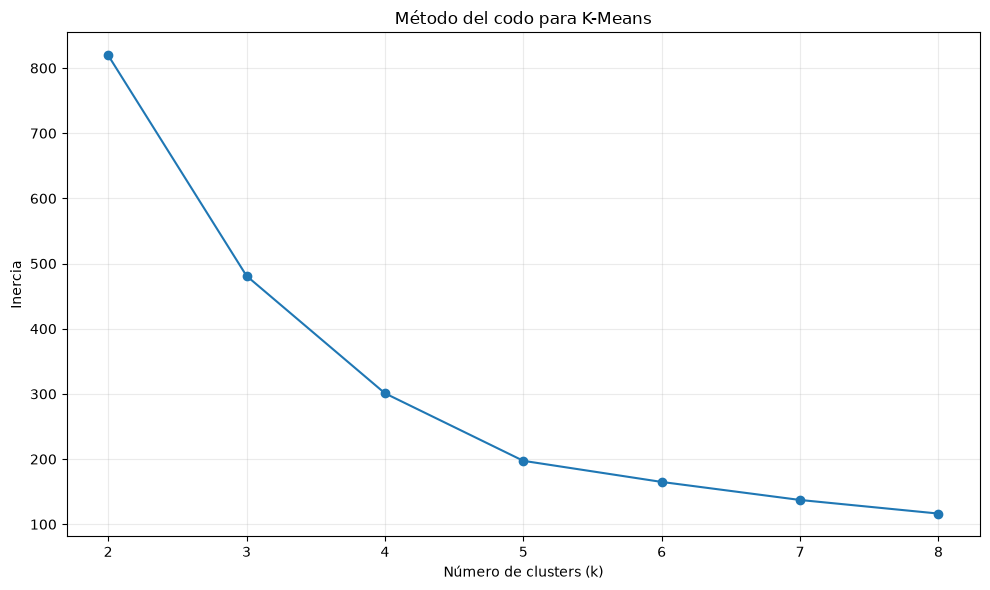

In [38]:
from sklearn.cluster import KMeans

inercia = []

for k in range(2, 9):
    modelo = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    
    modelo.fit(X_kmeans)
    inercia.append(modelo.inertia_)

plt.figure(figsize=(10, 6))

plt.plot(
    range(2, 9),
    inercia,
    marker="o"
)

plt.title("Método del codo para K-Means")
plt.xlabel("Número de clusters (k)")
plt.ylabel("Inercia")
plt.xticks(range(2, 9))
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

In [39]:
resultados_k = []

for k in [3, 4, 5]:
    modelo = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    
    modelo.fit(X_kmeans)
    
    resultados_k.append({
        "K": k,
        "Inercia": modelo.inertia_
    })

comparacion_k = pd.DataFrame(resultados_k)

display(comparacion_k)

,K,Inercia
0,3,481.151121
1,4,301.003501
2,5,197.369284


In [40]:
modelo_kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

datos_kmeans["CLUSTER"] = modelo_kmeans.fit_predict(X_kmeans)

print("K-Means ejecutado correctamente.")
print("\nCantidad de productos por cluster:")
print(datos_kmeans["CLUSTER"].value_counts().sort_index())

K-Means ejecutado correctamente.

Cantidad de productos por cluster:
CLUSTER
0     96
1    248
2      3
3      3
Name: count, dtype: int64


In [41]:
perfil_clusters = (
    datos_kmeans
    .groupby("CLUSTER")
    .agg(
        PRODUCTOS=("ITEM_CODE_MATCH", "count"),
        VENTAS_UNIDADES_PROMEDIO=("VENTAS_UNIDADES", "mean"),
        VENTAS_VALOR_PROMEDIO=("VENTAS_VALOR", "mean"),
        PROMEDIO_UNIDADES=("PROMEDIO_UNIDADES", "mean"),
        SEMANAS_ACTIVAS_PROMEDIO=("SEMANAS_ACTIVAS", "mean")
    )
    .round(2)
)

display(perfil_clusters)

,PRODUCTOS,VENTAS_UNIDADES_PROMEDIO,VENTAS_VALOR_PROMEDIO,PROMEDIO_UNIDADES,SEMANAS_ACTIVAS_PROMEDIO
CLUSTER,,,,,
0,96,30.17,586.59,2.66,13.02
1,248,1026.73,31419.67,7.93,77.66
2,3,41080.47,981556.00,88.28,80.00
3,3,3664.05,83266.67,145.10,80.00


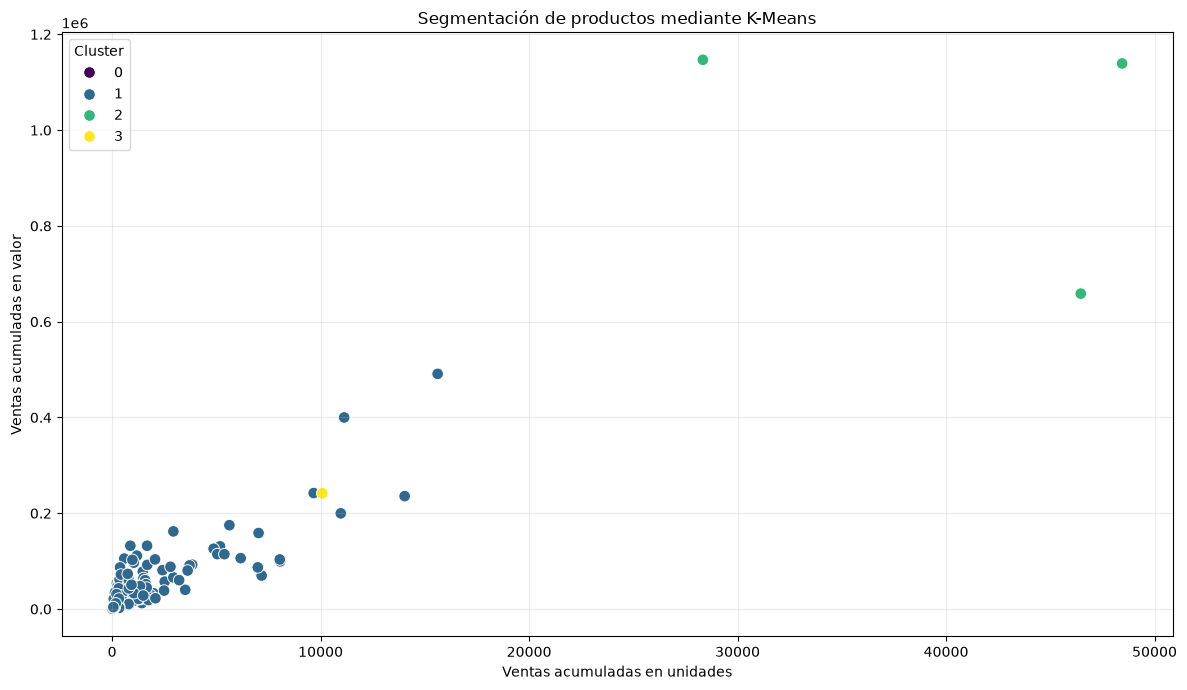

In [42]:
plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=datos_kmeans,
    x="VENTAS_UNIDADES",
    y="VENTAS_VALOR",
    hue="CLUSTER",
    palette="viridis",
    s=70
)

plt.title("Segmentación de productos mediante K-Means")
plt.xlabel("Ventas acumuladas en unidades")
plt.ylabel("Ventas acumuladas en valor")
plt.legend(title="Cluster")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

In [43]:
productos_extremos = (
    datos_kmeans[
        datos_kmeans["CLUSTER"].isin([2, 3])
    ]
    .sort_values(
        ["CLUSTER", "VENTAS_VALOR"],
        ascending=[True, False]
    )
)

display(
    productos_extremos[
        [
            "CLUSTER",
            "ITEM_CODE_MATCH",
            "BRAND",
            "VENTAS_UNIDADES",
            "VENTAS_VALOR",
            "PROMEDIO_UNIDADES",
            "SEMANAS_ACTIVAS"
        ]
    ]
)

,CLUSTER,ITEM_CODE_MATCH,BRAND,VENTAS_UNIDADES,VENTAS_VALOR,PROMEDIO_UNIDADES,SEMANAS_ACTIVAS
4,2,0000075000639,CLORALEX,28334.417,1146849.632,60.226977,80
3,2,0000075000622,CLORALEX,48445.151,1139233.787,112.098525,80
2,2,0000075000615,CLORALEX,46461.839,658584.568,92.527904,80
134,3,7501025450212,CLORALEX,10079.695,241498.884,127.815700,80
73,3,7501025401252,CLORALUZ,798.024,7374.786,96.689900,80
305,3,7501681100018,BANDERA,114.418,926.341,210.782563,80


,CLUSTER,PRODUCTOS
0,0,96
1,1,248
2,2,3
3,3,3


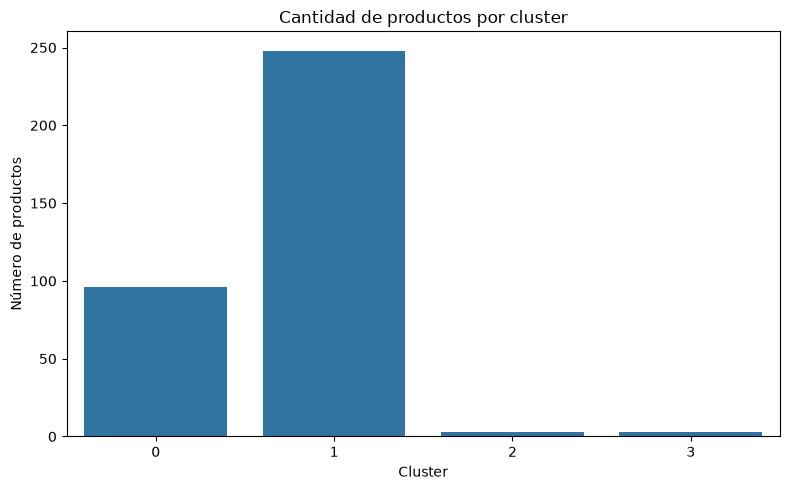

In [44]:
cantidad_clusters = (
    datos_kmeans["CLUSTER"]
    .value_counts()
    .sort_index()
    .reset_index()
)

cantidad_clusters.columns = ["CLUSTER", "PRODUCTOS"]

display(cantidad_clusters)

plt.figure(figsize=(8, 5))

sns.barplot(
    data=cantidad_clusters,
    x="CLUSTER",
    y="PRODUCTOS"
)

plt.title("Cantidad de productos por cluster")
plt.xlabel("Cluster")
plt.ylabel("Número de productos")
plt.tight_layout()
plt.show()

In [45]:
# Copias de las tablas originales para exportación
sql_fact_sales = fact_sales.copy()
sql_dim_product = dim_product.copy()
sql_dim_calendar = dim_calendar.copy()
sql_dim_category = dim_category.copy()
sql_dim_segment = dim_segment.copy()

print("Tablas preparadas para SQL Server:")
print("FACT_SALES:", sql_fact_sales.shape)
print("DIM_PRODUCT:", sql_dim_product.shape)
print("DIM_CALENDAR:", sql_dim_calendar.shape)
print("DIM_CATEGORY:", sql_dim_category.shape)
print("DIM_SEGMENT:", sql_dim_segment.shape)

Tablas preparadas para SQL Server:
FACT_SALES: (122002, 9)
DIM_PRODUCT: (505, 11)
DIM_CALENDAR: (156, 5)
DIM_CATEGORY: (5, 2)
DIM_SEGMENT: (53, 6)


In [46]:
sql_fact_sales.to_csv(
    "FACT_SALES_SQL.csv",
    index=False,
    encoding="utf-8-sig"
)

sql_dim_product.to_csv(
    "DIM_PRODUCT_SQL.csv",
    index=False,
    encoding="utf-8-sig"
)

sql_dim_calendar.to_csv(
    "DIM_CALENDAR_SQL.csv",
    index=False,
    encoding="utf-8-sig"
)

sql_dim_category.to_csv(
    "DIM_CATEGORY_SQL.csv",
    index=False,
    encoding="utf-8-sig"
)

sql_dim_segment.to_csv(
    "DIM_SEGMENT_SQL.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Los 5 archivos se exportaron correctamente.")

Los 5 archivos se exportaron correctamente.


In [47]:
import os

print("Carpeta donde se guardaron los archivos:")
print(os.getcwd())

print("\nArchivos CSV disponibles:")
for archivo in os.listdir():
    if archivo.endswith(".csv") and "_SQL" in archivo:
        print(archivo)

Carpeta donde se guardaron los archivos:
C:\Users\Genesis

Archivos CSV disponibles:
DIM_CALENDAR_SQL.csv
DIM_CATEGORY_SQL.csv
DIM_PRODUCT_SQL.csv
DIM_SEGMENT_SQL.csv
FACT_SALES_SQL.csv


In [50]:

print(ventas_semana.head())

print("\nColumnas disponibles:")
print(ventas_semana.columns.tolist())

print("\nNúmero de semanas:")
print(len(ventas_semana))


        DATE  VENTAS_UNIDADES  VENTAS_VALOR
0 2022-01-09         5661.824    151538.922
1 2022-01-16         5686.147    146996.991
2 2022-01-23         4844.874    125351.336
3 2022-01-30         4793.584    123945.617
4 2022-02-06         5021.274    129841.767

Columnas disponibles:
['DATE', 'VENTAS_UNIDADES', 'VENTAS_VALOR']

Número de semanas:
80


In [51]:

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# Ordenar las ventas por fecha
datos_prediccion = ventas_semana.sort_values("DATE").copy()
datos_prediccion = datos_prediccion.reset_index(drop=True)

# Crear una variable que represente el paso de las semanas
datos_prediccion["SEMANA"] = np.arange(len(datos_prediccion))

# Separar 80% para entrenamiento y 20% para evaluación
corte = int(len(datos_prediccion) * 0.80)

entrenamiento = datos_prediccion.iloc[:corte]
prueba = datos_prediccion.iloc[corte:]

X_train = entrenamiento[["SEMANA"]]
y_train = entrenamiento["VENTAS_VALOR"]

X_test = prueba[["SEMANA"]]
y_test = prueba["VENTAS_VALOR"]

# Entrenar el modelo
modelo_regresion = LinearRegression()
modelo_regresion.fit(X_train, y_train)

# Predecir las ventas del periodo de prueba
predicciones = modelo_regresion.predict(X_test)

# Evaluar el modelo
mae = mean_absolute_error(y_test, predicciones)
mse = mean_squared_error(y_test, predicciones)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, predicciones)

print("RESULTADOS DEL MODELO DE REGRESIÓN LINEAL")
print("Semanas para entrenamiento:", len(entrenamiento))
print("Semanas para evaluación:", len(prueba))
print("MAE:", round(mae, 2))
print("MSE:", round(mse, 2))
print("RMSE:", round(rmse, 2))
print("R²:", round(r2, 4))


RESULTADOS DEL MODELO DE REGRESIÓN LINEAL
Semanas para entrenamiento: 64
Semanas para evaluación: 16
MAE: 14183.75
MSE: 445546824.64
RMSE: 21107.98
R²: -0.5465


In [52]:

# Crear una copia de las ventas semanales
datos_modelo = ventas_semana.sort_values("DATE").copy()
datos_modelo = datos_modelo.reset_index(drop=True)

# Usar ventas anteriores como variables
datos_modelo["VENTA_ANTERIOR"] = datos_modelo["VENTAS_VALOR"].shift(1)
datos_modelo["VENTA_HACE_2_SEMANAS"] = datos_modelo["VENTAS_VALOR"].shift(2)
datos_modelo["PROMEDIO_4_SEMANAS"] = (
    datos_modelo["VENTAS_VALOR"].shift(1).rolling(4).mean()
)

# Eliminar filas sin datos anteriores
datos_modelo = datos_modelo.dropna().reset_index(drop=True)

# Separar entrenamiento y prueba respetando el tiempo
corte = int(len(datos_modelo) * 0.80)
entrenamiento = datos_modelo.iloc[:corte]
prueba = datos_modelo.iloc[corte:]

variables = [
    "VENTA_ANTERIOR",
    "VENTA_HACE_2_SEMANAS",
    "PROMEDIO_4_SEMANAS"
]

X_train = entrenamiento[variables]
y_train = entrenamiento["VENTAS_VALOR"]
X_test = prueba[variables]
y_test = prueba["VENTAS_VALOR"]

# Entrenar el modelo
modelo_ventas = LinearRegression()
modelo_ventas.fit(X_train, y_train)

# Predecir ventas
predicciones_nuevo = modelo_ventas.predict(X_test)

# Evaluar el modelo
mae_nuevo = mean_absolute_error(y_test, predicciones_nuevo)
rmse_nuevo = np.sqrt(mean_squared_error(y_test, predicciones_nuevo))
r2_nuevo = r2_score(y_test, predicciones_nuevo)

print("RESULTADOS DEL MODELO CON VENTAS ANTERIORES")
print("MAE:", round(mae_nuevo, 2))
print("RMSE:", round(rmse_nuevo, 2))
print("R²:", round(r2_nuevo, 4))


RESULTADOS DEL MODELO CON VENTAS ANTERIORES
MAE: 12322.19
RMSE: 19278.88
R²: -0.2901


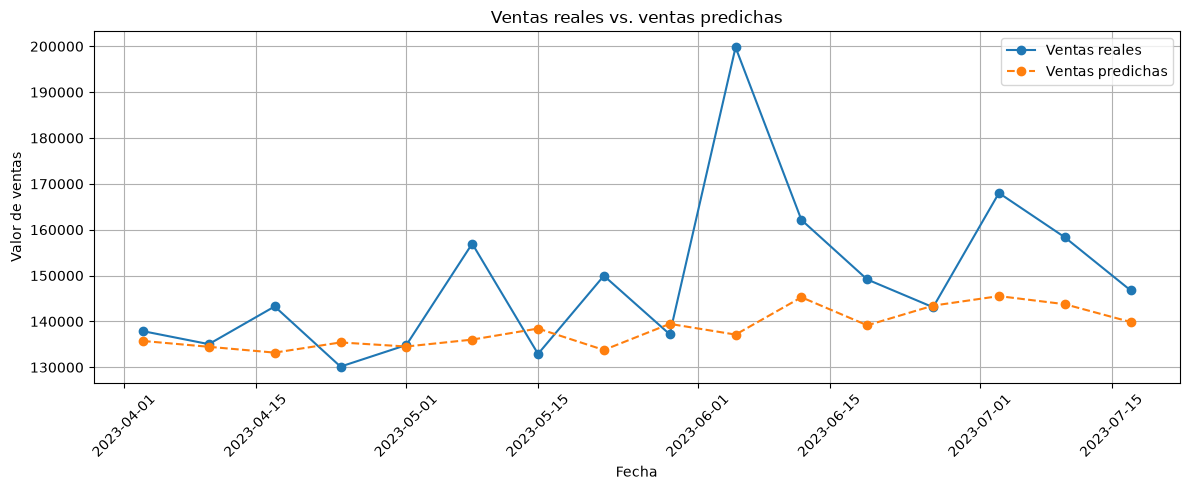

In [53]:

plt.figure(figsize=(12, 5))

plt.plot(
    prueba["DATE"],
    y_test,
    marker="o",
    label="Ventas reales"
)

plt.plot(
    prueba["DATE"],
    predicciones_nuevo,
    marker="o",
    linestyle="--",
    label="Ventas predichas"
)

plt.title("Ventas reales vs. ventas predichas")
plt.xlabel("Fecha")
plt.ylabel("Valor de ventas")
plt.xticks(rotation=45)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


In [54]:

# Tomar las últimas observaciones disponibles
historial = datos_modelo.copy()
pronosticos_futuros = []

for i in range(8):
    ultima_venta = historial["VENTAS_VALOR"].iloc[-1]
    venta_hace_2 = historial["VENTAS_VALOR"].iloc[-2]
    promedio_4 = historial["VENTAS_VALOR"].tail(4).mean()

    nuevos_datos = pd.DataFrame([{
        "VENTA_ANTERIOR": ultima_venta,
        "VENTA_HACE_2_SEMANAS": venta_hace_2,
        "PROMEDIO_4_SEMANAS": promedio_4
    }])

    prediccion = modelo_ventas.predict(nuevos_datos[variables])[0]

    nueva_fecha = historial["DATE"].iloc[-1] + pd.Timedelta(weeks=1)

    pronosticos_futuros.append({
        "DATE": nueva_fecha,
        "VENTAS_VALOR_PREDICHO": prediccion
    })

    nueva_fila = pd.DataFrame([{
        "DATE": nueva_fecha,
        "VENTAS_VALOR": prediccion,
        "VENTA_ANTERIOR": ultima_venta,
        "VENTA_HACE_2_SEMANAS": venta_hace_2,
        "PROMEDIO_4_SEMANAS": promedio_4
    }])

    historial = pd.concat([historial, nueva_fila], ignore_index=True)

pronostico_8_semanas = pd.DataFrame(pronosticos_futuros)

print("PRONÓSTICO PARA LAS PRÓXIMAS 8 SEMANAS")
print(pronostico_8_semanas.round(2).to_string(index=False))


PRONÓSTICO PARA LAS PRÓXIMAS 8 SEMANAS
      DATE  VENTAS_VALOR_PREDICHO
2023-07-24              140481.91
2023-07-31              141480.76
2023-08-07              139528.17
2023-08-14              137360.78
2023-08-21              136551.39
2023-08-28              136388.62
2023-09-04              135951.64
2023-09-11              135582.62


C:\Users\Genesis\AppData\Local\Temp\ipykernel_20384\1222577665.py:38: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  print(pronostico_8_semanas.round(2).to_string(index=False))


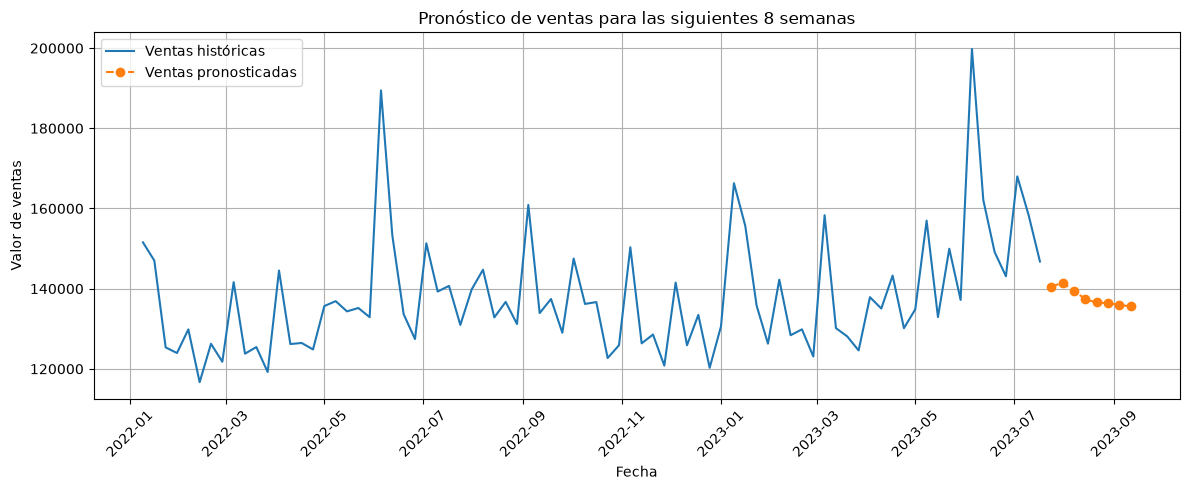

In [56]:

plt.figure(figsize=(12, 5))

plt.plot(
    ventas_semana["DATE"],
    ventas_semana["VENTAS_VALOR"],
    label="Ventas históricas"
)

plt.plot(
    pronostico_8_semanas["DATE"],
    pronostico_8_semanas["VENTAS_VALOR_PREDICHO"],
    marker="o",
    linestyle="--",
    label="Ventas pronosticadas"
)

plt.title("Pronóstico de ventas para las siguientes 8 semanas")
plt.xlabel("Fecha")
plt.ylabel("Valor de ventas")
plt.xticks(rotation=45)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


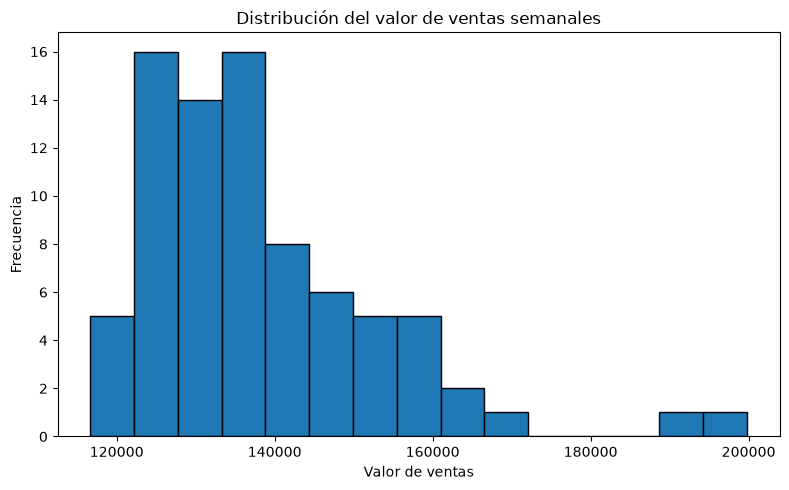

In [57]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.hist(ventas_semana["VENTAS_VALOR"], bins=15, edgecolor="black")
plt.title("Distribución del valor de ventas semanales")
plt.xlabel("Valor de ventas")
plt.ylabel("Frecuencia")
plt.tight_layout()
plt.show()

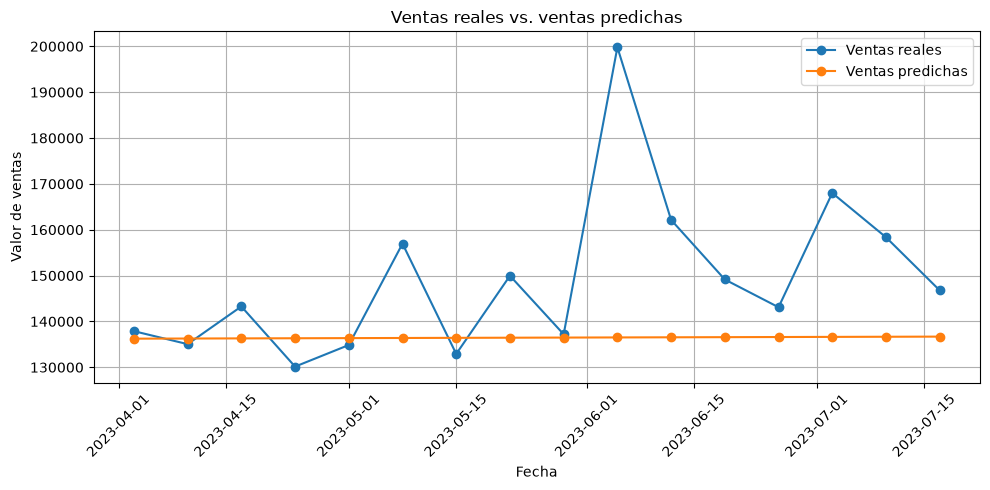

In [58]:
plt.figure(figsize=(10, 5))

plt.plot(prueba["DATE"], y_test,
         marker="o", label="Ventas reales")

plt.plot(prueba["DATE"], predicciones,
         marker="o", label="Ventas predichas")

plt.title("Ventas reales vs. ventas predichas")
plt.xlabel("Fecha")
plt.ylabel("Valor de ventas")
plt.xticks(rotation=45)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()